### ====================================================
### Прогонка по разным методам регуляризации
### ====================================================

In [2]:
# ==============================================================================
# 1: Импорты
# ==============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

from Magnetic_Field import (
    make_A_phi, A_phi_gaussian, A_phi_uniform, A_phi_power, A_phi_screen,
    compute_B_from_A_phi, extract_axial_profiles,
    save_field_to_csv, load_field_from_csv,
    compute_field_from_B
)
from methods import (
    build_operators, forward_rm, regularizer, RegularizedInversion,
    choose_alpha_lcurve, electron_density, rel_error, relative_error,
    add_noise, plot_recovery, plot_sweep, plot_A_and_B,
    plot_A_phi_profiles, plot_B_profiles, 
    append_run_to_csv, load_runs,
    plot_all_true_fields, plot_all_recovered_fields,
    plot_all_rm, plot_all_rm_noisy,
)

try:
    plt.style.use('seaborn-v0_8-whitegrid')
except OSError:
    plt.style.use('default')

print("✅ Модули загружены.")



✅ Модули загружены.


In [7]:
deltas = [0, 0.005, 0.01, 0.02, 0.03]

In [8]:
# ==============================================================================
# Прогон 4 методов регуляризации
# ==============================================================================

reg_kinds = ["none", "zero_order", "first_order", "second_order"]

# имена папок/файлов для каждого метода
REG_TAG = {
    "none":         "no_reg",
    "zero_order":   "reg_0",
    "first_order":  "reg_1",
    "second_order": "reg_2",
}

RESULTS_DIR = "results"
os.makedirs(RESULTS_DIR, exist_ok=True)


In [10]:
def B_z_constant(rho, B0=1.0):
    return B0 * rho**0

def B_z_gauss(rho, B0=1.0, rho_scale=1.0):
    return B0 * np.exp(-(rho / rho_scale)**2)

def B_z_power2(rho, B0=0.0025):
    return B0 * rho**2

def B_z_gauss_power2(rho, B0=1.0, rho_scale=1.0):
    return B0 * rho**2 * np.exp(-(rho / rho_scale)**2)

variants_B = {
    "B_constant":  B_z_constant,
    r"B_power2_B0_01":  B_z_power2,
    r"B_$e^{-\rho^2}$": B_z_gauss,
    r"B_$\rho^2 e^{-\rho^2}$": B_z_gauss_power2,
}


In [11]:

def get_Filename(delta, reg_kind):
    return f"2110/ALL_TESTS_Bz_runs_noise_{delta}_reg_{reg_kind}.csv"

In [ ]:

for REG_KIND in reg_kinds:
    for delta_tmp in deltas:
        fname = os.path.join(
            RESULTS_DIR,
            get_Filename(delta_tmp, REG_TAG[REG_KIND])
        )
        if os.path.exists(fname):
            os.remove(fname)              # чистая перезапись

        for name, func in variants_B.items():
            Calculate(
                B_z_func=func,
                mode="direct",
                delta=delta_tmp,
                reg_kind=REG_KIND,        # <-- ключевой параметр
                plot=False,
                filename=fname,
                run_name=name,
                seed=42,
            )

💾 Запуск 'B_constant' добавлен в results\results/ALL_TESTS_runs_var_B_noise_0_reg_no_reg.csv
💾 Запуск 'B_power2_B0_01' добавлен в results\results/ALL_TESTS_runs_var_B_noise_0_reg_no_reg.csv
💾 Запуск 'B_$e^{-\rho^2}$' добавлен в results\results/ALL_TESTS_runs_var_B_noise_0_reg_no_reg.csv
💾 Запуск 'B_$\rho^2 e^{-\rho^2}$' добавлен в results\results/ALL_TESTS_runs_var_B_noise_0_reg_no_reg.csv
💾 Запуск 'B_constant' добавлен в results\results/ALL_TESTS_runs_var_B_noise_0.005_reg_no_reg.csv
💾 Запуск 'B_power2_B0_01' добавлен в results\results/ALL_TESTS_runs_var_B_noise_0.005_reg_no_reg.csv
💾 Запуск 'B_$e^{-\rho^2}$' добавлен в results\results/ALL_TESTS_runs_var_B_noise_0.005_reg_no_reg.csv
💾 Запуск 'B_$\rho^2 e^{-\rho^2}$' добавлен в results\results/ALL_TESTS_runs_var_B_noise_0.005_reg_no_reg.csv
💾 Запуск 'B_constant' добавлен в results\results/ALL_TESTS_runs_var_B_noise_0.01_reg_no_reg.csv
💾 Запуск 'B_power2_B0_01' добавлен в results\results/ALL_TESTS_runs_var_B_noise_0.01_reg_no_reg.csv
💾 

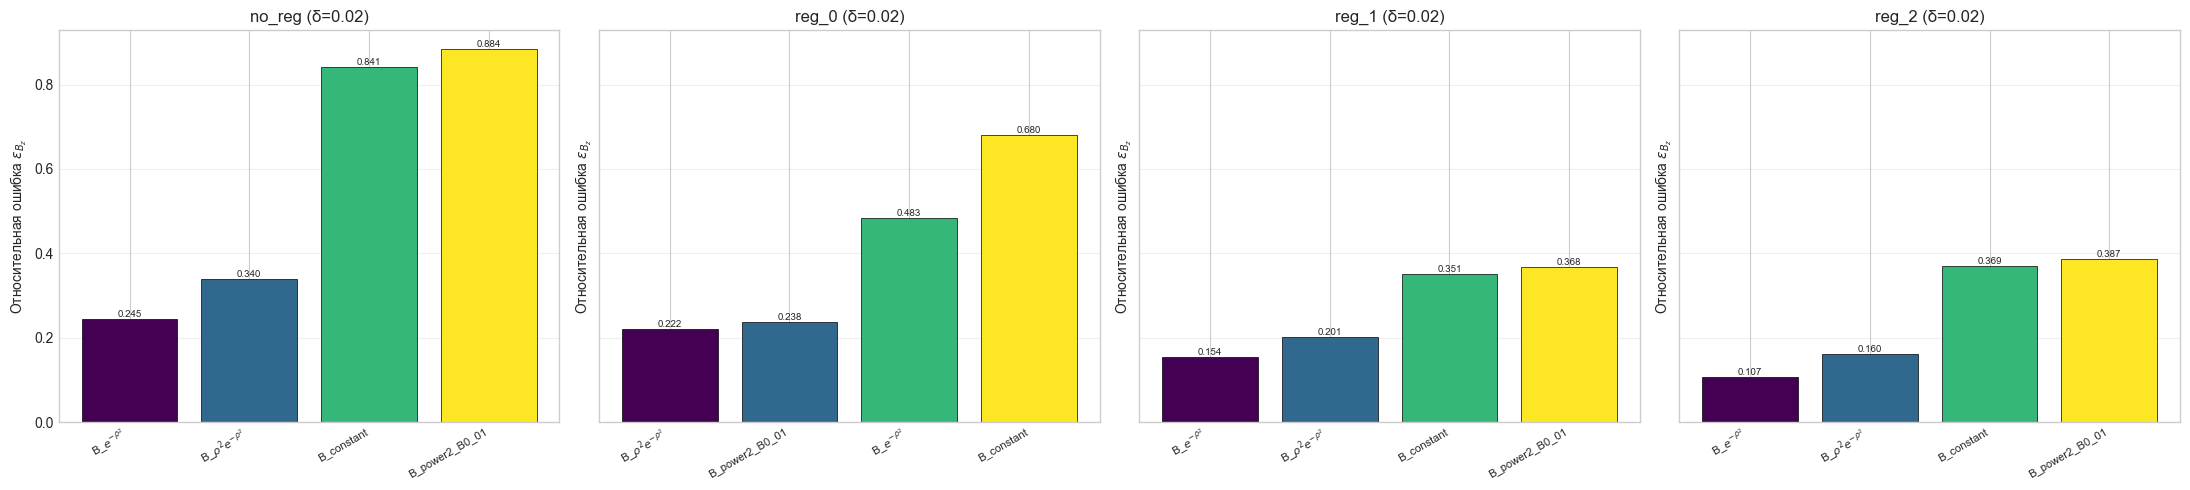

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(22, 5), sharey=True)
chooise_noise = 0.02
for ax, reg in zip(axes, reg_kinds):
    fname = os.path.join(
        RESULTS_DIR,
        f"results/ALL_TESTS_runs_var_B_noise_{chooise_noise}_reg_{REG_TAG[reg]}.csv"
    )
    if not os.path.exists(fname):
        ax.set_title(f"{reg} — нет файла"); continue
        
    rho, runs = load_runs(fname)
    plot_all_errors_bar(rho, runs, err_key='err_Bz',
                        title=f"{REG_TAG[reg]} (δ={chooise_noise})", ax=ax)

plt.tight_layout(); plt.show()

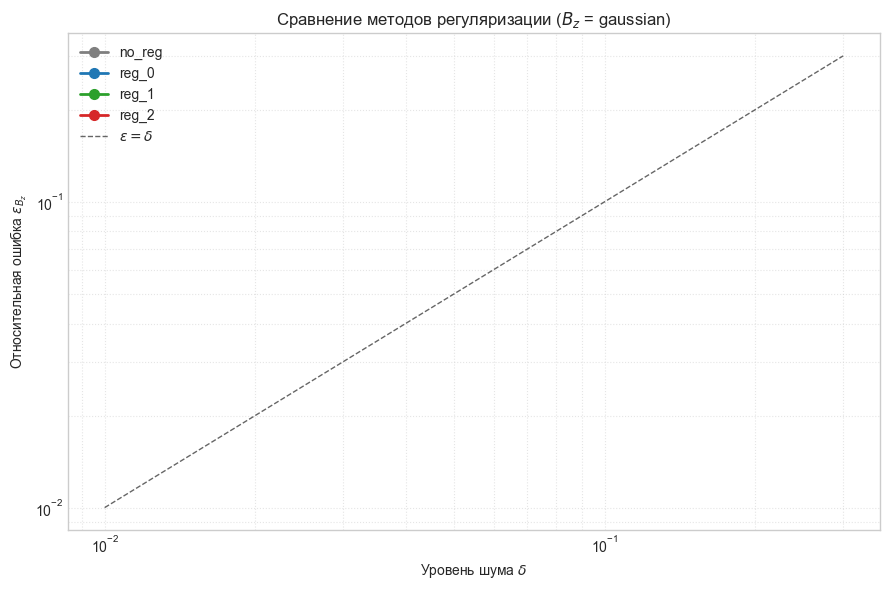

In [ ]:
fig, ax = plt.subplots(figsize=(9, 6))

colors = {"none": "tab:gray", "zero_order": "tab:blue",
          "first_order": "tab:green", "second_order": "tab:red"}

for reg in reg_kinds:
    ds, es = [], []
    for d in deltas:
        fname = os.path.join(
            RESULTS_DIR,
            f"results/ALL_TESTS_runs_var_B_noise_{d}_reg_{REG_TAG[reg]}.csv"
        )
        if not os.path.exists(fname): continue
        _, runs = load_runs(fname)
        if "B_gauss" in runs and "err_Bz" in runs["B_gauss"]:
            ds.append(d)
            es.append(float(np.mean(runs["B_gauss"]["err_Bz"])))

    ds_plot = [max(x, 1e-6) for x in ds]
    es_plot = [max(x, 1e-6) for x in es]
    ax.loglog(ds_plot, es_plot, "o-", color=colors[reg],
              lw=2, ms=7, label=REG_TAG[reg])

# линия ε = δ
xx = np.logspace(np.log10(1e-2), np.log10(0.3), 50)
ax.loglog(xx, xx, "k--", lw=1, alpha=0.6, label=r"$\varepsilon = \delta$")

ax.set_xlabel(r"Уровень шума $\delta$")
ax.set_ylabel(r"Относительная ошибка $\varepsilon_{B_z}$")
ax.set_title(r"Сравнение методов регуляризации ($B_z$ = gaussian)")
ax.grid(True, which="both", ls=":", alpha=0.5)
ax.legend()
plt.tight_layout(); plt.show()

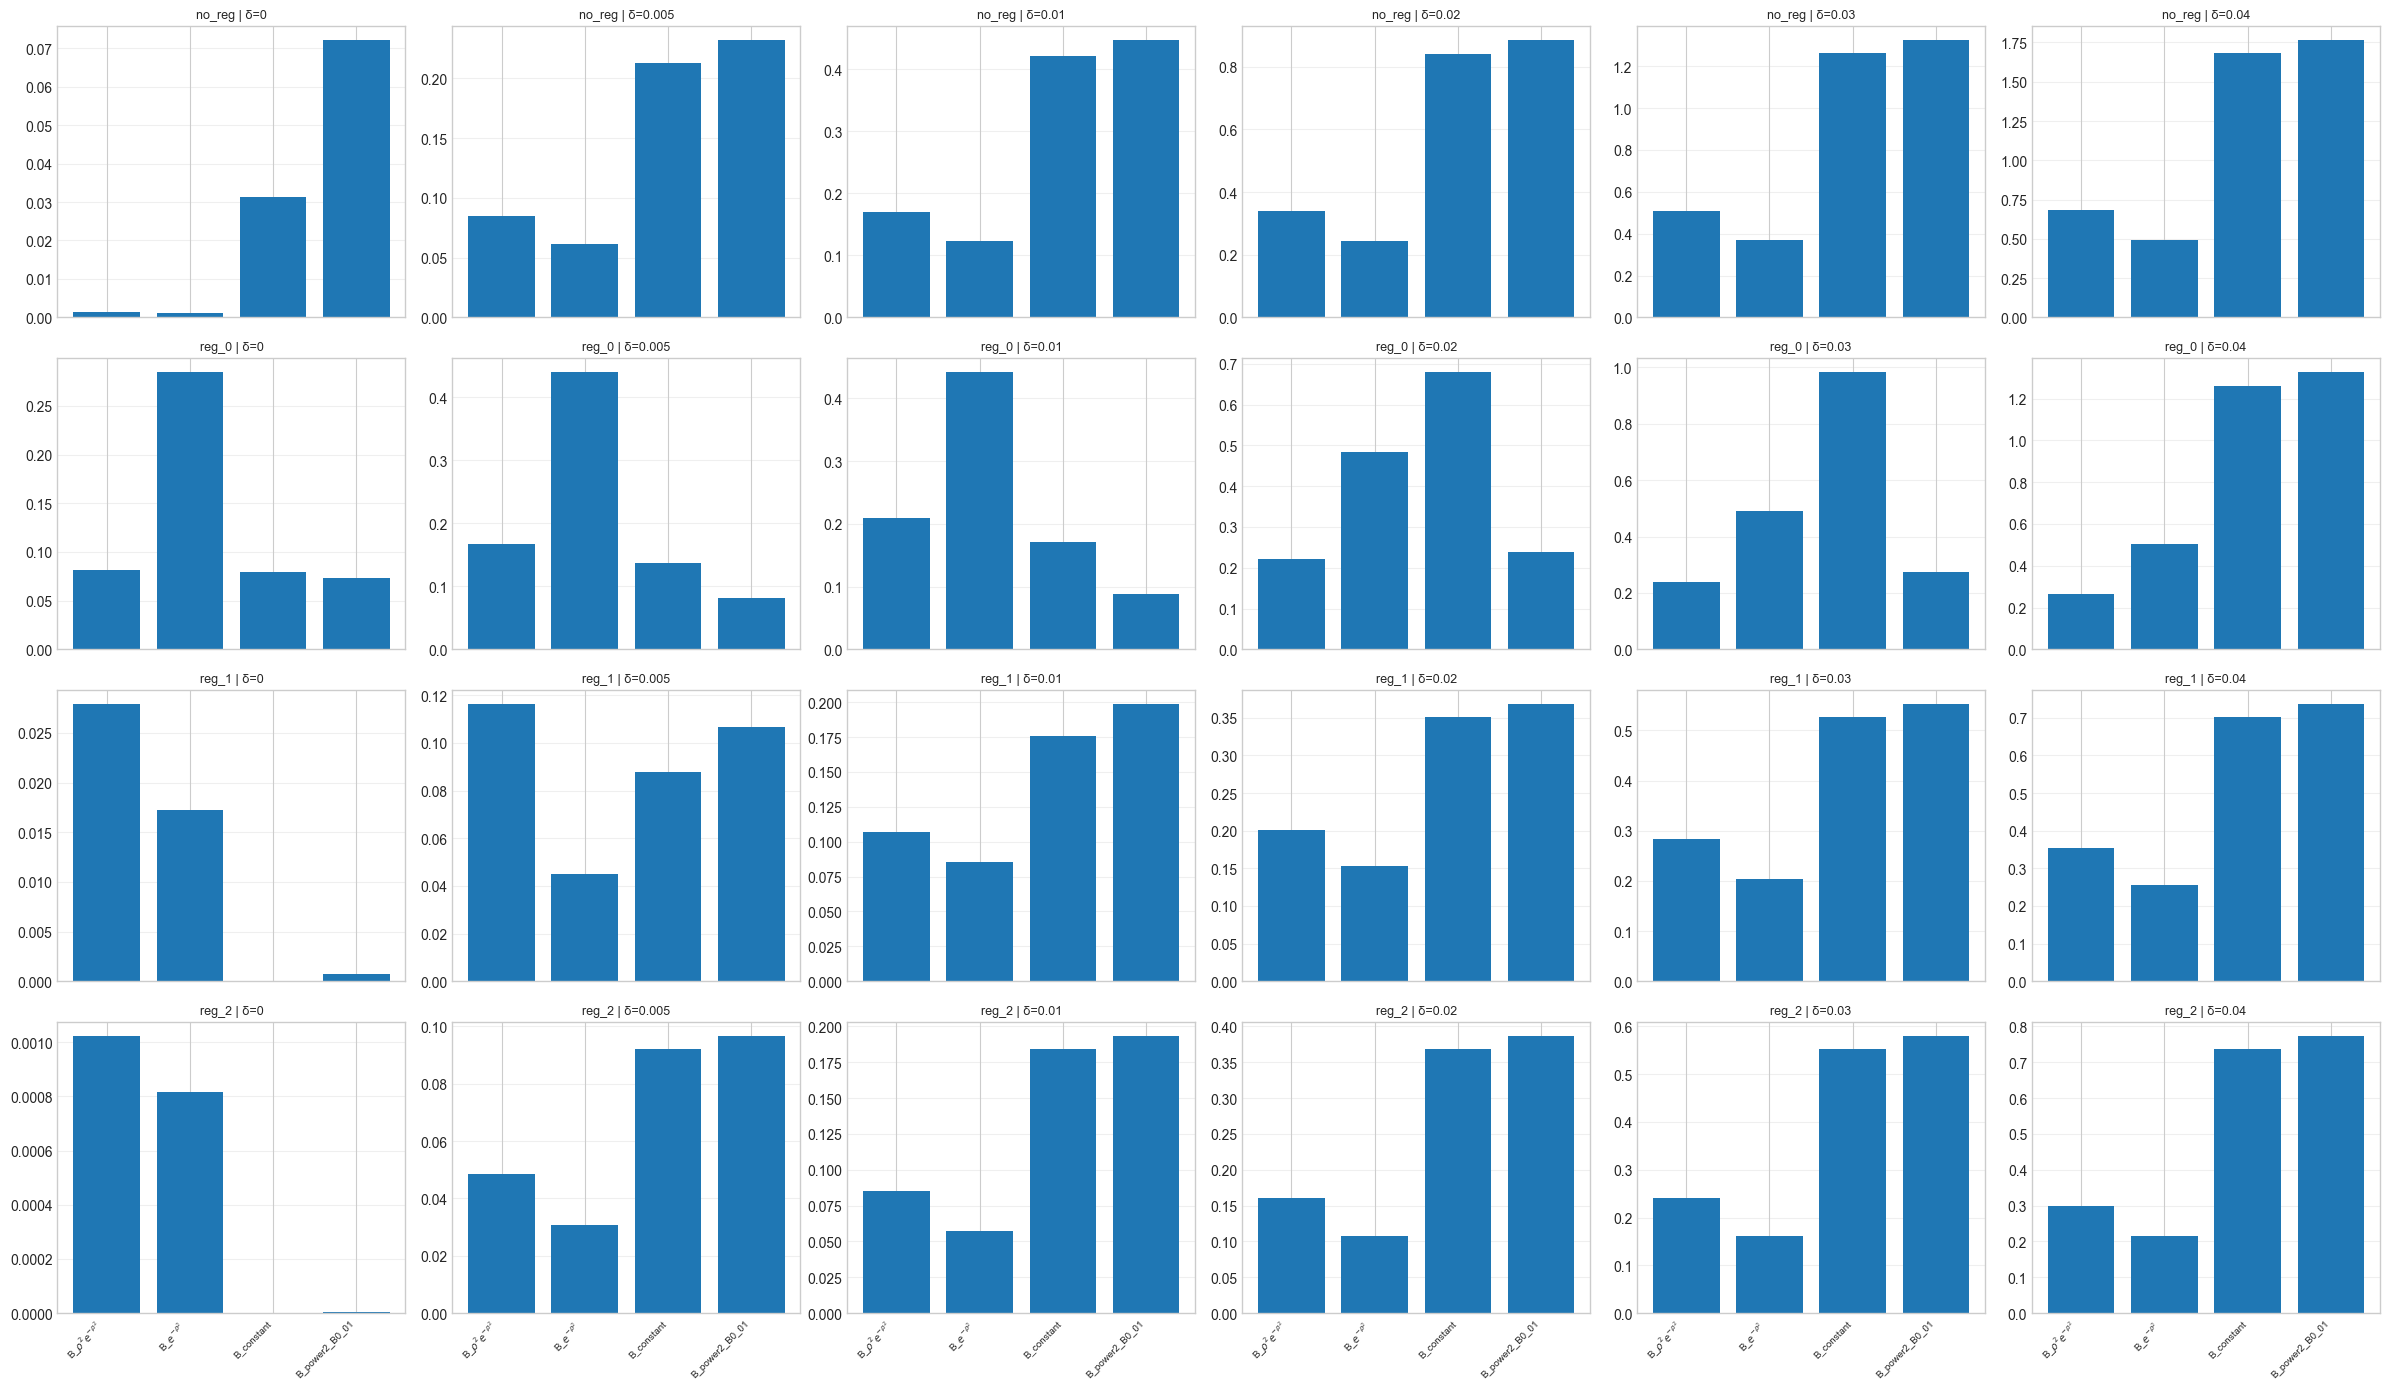

In [ ]:
n_reg = len(reg_kinds)
n_d   = len(deltas)

fig, axes = plt.subplots(n_reg, n_d,
                         figsize=(4*n_d, 3.5*n_reg),
                         sharex=True, sharey=False)

for i, reg in enumerate(reg_kinds):
    for j, d in enumerate(deltas):
        ax = axes[i, j]
        fname = os.path.join(
            RESULTS_DIR,
            f"results/ALL_TESTS_runs_var_B_noise_{d}_reg_{REG_TAG[reg]}.csv"
        )
        if not os.path.exists(fname):
            ax.set_title(f"{REG_TAG[reg]} δ={d} — нет файла", fontsize=9)
            ax.axis("off"); continue
        _, runs = load_runs(fname)
        vals, names = [], []
        for name, dd in runs.items():
            if "err_Bz" in dd:
                vals.append(float(np.mean(dd["err_Bz"])))
                names.append(name)
        ax.bar(range(len(vals)), vals)
        ax.set_xticks(range(len(vals)))
        ax.set_xticklabels(names, rotation=45, ha="right", fontsize=7)
        ax.set_title(f"{REG_TAG[reg]} | δ={d}", fontsize=9)
        ax.grid(axis="y", alpha=0.3)

plt.tight_layout(); plt.show()